# Stability-Aware Customer Segmentation

This notebook selects customer segments using **both cluster quality (compactness/separation) and cluster stability** under resampling.

**Pipeline**
1. Build / load customer RFM data and preprocess
2. Define candidate models (K-Means, Ward, Gaussian Mixture, DBSCAN)
3. Score **quality** (silhouette, Calinski-Harabasz, Davies-Bouldin)
4. Score **stability** by re-clustering perturbed data (80% subsamples and noise injection) and measuring Adjusted Rand Index (ARI) against the reference clustering
5. Combine quality and stability into one selection score (harmonic mean), apply a parsimony rule
6. Check weight sensitivity and per-segment (Jaccard) stability
7. Profile the final segments

To use your own data, set `DATA_PATH` in the config cell to a CSV with `recency`, `frequency`, `monetary` columns.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
warnings.filterwarnings("ignore")

# ---------------- Configuration ----------------
SEED = 42
DATA_PATH = None                  # e.g. "customers.csv"; None = synthetic data
FEATURES = ["recency", "frequency", "monetary"]
B = 50                            # resamples per perturbation type (use 100+ for final results)
SUBSAMPLE_FRAC = 0.8              # fraction kept in each subsample
NOISE_SD = 0.15                   # Gaussian noise (in standardized units)
K_RANGE = range(2, 9)
DBSCAN_EPS = [0.3, 0.5, 0.7]
DBSCAN_MIN_SAMPLES = 20
PARSIMONY_TOL = 0.02              # prefer fewer clusters if score is within this of the best
JACCARD_THRESHOLD = 0.75          # segments below this are flagged unreliable

## 1. Data and preprocessing

In [2]:
def make_synthetic(n=1500, seed=SEED):
    rng = np.random.default_rng(seed)
    # (share, name, mean of [log recency, log frequency, log monetary])
    specs = [(0.35, "Champions", [2.0, 2.8, 6.5]),
             (0.30, "Regulars",  [3.5, 1.8, 4.8]),
             (0.20, "At-risk",   [4.8, 1.3, 4.4]),
             (0.15, "Lost/low",  [5.6, 0.5, 3.0])]
    parts = []
    for share, name, mu in specs:
        m = int(n * share)
        z = rng.normal(mu, 0.55, size=(m, 3))
        parts.append(pd.DataFrame(np.expm1(z), columns=FEATURES).assign(true_segment=name))
    return pd.concat(parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

df = make_synthetic() if DATA_PATH is None else pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())

# Log-transform skewed features. Scaling is re-fit inside each resample later (no leakage).
Xlog = np.log1p(df[FEATURES].clip(lower=0).values)
X = StandardScaler().fit_transform(Xlog)   # reference (full-data) representation

(1500, 4)


,recency,frequency,monetary,true_segment
0,162.468041,1.215821,83.412770,At-risk
1,221.867259,1.526068,4.310904,Lost/low
2,3.665377,22.668495,950.116876,Champions
3,16.348986,32.193015,382.480860,Champions
4,7.970532,46.093036,858.540302,Champions


## 2. Candidate models

In [3]:
def make_candidates():
    c = {}
    for k in K_RANGE:
        c[f"kmeans_k{k}"] = lambda k=k: KMeans(k, n_init=5, random_state=SEED)
        c[f"ward_k{k}"]   = lambda k=k: AgglomerativeClustering(n_clusters=k, linkage="ward")
        c[f"gmm_k{k}"]    = lambda k=k: GaussianMixture(k, random_state=SEED)
    for eps in DBSCAN_EPS:
        c[f"dbscan_eps{eps}"] = lambda e=eps: DBSCAN(eps=e, min_samples=DBSCAN_MIN_SAMPLES)
    return c

candidates = make_candidates()
print(len(candidates), "candidate models")

24 candidate models


## 3. Quality metrics

DBSCAN noise points (label −1) are excluded when computing quality, and a model needs at least 2 clusters to be scored.

In [4]:
def quality(Z, labels):
    m = labels != -1
    if m.sum() < 10 or len(np.unique(labels[m])) < 2:
        return None
    return (silhouette_score(Z[m], labels[m]),
            calinski_harabasz_score(Z[m], labels[m]),
            davies_bouldin_score(Z[m], labels[m]))

## 4. Stability under perturbation

Two perturbation types, each repeated `B` times:
- **Subsampling:** keep a random 80% of customers (scaler re-fit on the subsample), re-cluster, compare to the reference labels **on the same customers**.
- **Noise injection:** add Gaussian jitter to the standardized features and re-cluster.

Agreement is measured with ARI, which is invariant to label permutation. Every candidate sees the same perturbations (same seed). For DBSCAN, noise (−1) is treated as its own label when computing ARI.

In [5]:
def stability(make, ref_labels, mode, B=B):
    rng = np.random.default_rng(SEED)      # same perturbations for every candidate
    n, out = len(X), []
    for _ in range(B):
        if mode == "subsample":
            idx = rng.choice(n, int(SUBSAMPLE_FRAC * n), replace=False)
            Z = StandardScaler().fit_transform(Xlog[idx])
        else:
            idx = np.arange(n)
            Z = X + rng.normal(0, NOISE_SD, X.shape)
        lab = make().fit_predict(Z)
        out.append(adjusted_rand_score(ref_labels[idx], lab))
    return np.array(out)

rows, ref_store, skipped = [], {}, []
for name, make in candidates.items():
    ref = make().fit_predict(X)
    q = quality(X, ref)
    if q is None:
        skipped.append(name); continue
    ref_store[name] = ref
    s_sub = stability(make, ref, "subsample")
    s_noi = stability(make, ref, "noise")
    rows.append(dict(
        model=name, algo=name.split("_")[0],
        n_clusters=len(set(ref) - {-1}), noise_frac=(ref == -1).mean(),
        sil=q[0], ch=q[1], db=q[2],
        ari_sub=s_sub.mean(), ari_sub_sd=s_sub.std(),
        ari_noise=s_noi.mean(), ari_noise_sd=s_noi.std()))

res = pd.DataFrame(rows)
print("Skipped (fewer than 2 clusters):", skipped)
res.round(3).head(10)

Skipped (fewer than 2 clusters): ['dbscan_eps0.5', 'dbscan_eps0.7']


,model,algo,n_clusters,noise_frac,sil,ch,db,ari_sub,ari_sub_sd,ari_noise,ari_noise_sd
0,kmeans_k2,kmeans,2,0.0,0.495,2388.773,0.711,0.987,0.012,0.890,0.016
1,ward_k2,ward,2,0.0,0.498,2200.000,0.672,0.933,0.096,0.895,0.096
2,gmm_k2,gmm,2,0.0,0.478,1925.181,0.670,0.989,0.006,0.945,0.010
3,kmeans_k3,kmeans,3,0.0,0.445,2432.320,0.825,0.981,0.013,0.910,0.009
4,ward_k3,ward,3,0.0,0.438,2209.039,0.769,0.840,0.120,0.778,0.114
5,gmm_k3,gmm,3,0.0,0.446,2362.444,0.790,0.962,0.024,0.910,0.014
6,kmeans_k4,kmeans,4,0.0,0.380,2090.013,1.030,0.977,0.019,0.883,0.014
7,ward_k4,ward,4,0.0,0.359,1957.512,1.076,0.788,0.053,0.720,0.038
8,gmm_k4,gmm,4,0.0,0.378,2066.974,1.035,0.857,0.196,0.745,0.182
9,kmeans_k5,kmeans,5,0.0,0.299,1815.587,1.215,0.957,0.068,0.810,0.047


## 5. Combined selection criterion

- **Q** = mean of min-max-normalized silhouette, Calinski-Harabasz, and (1 − Davies-Bouldin)
- **Stab** = average over the two perturbation types of `mean(ARI) − SD(ARI)` (penalizes inconsistency), clipped to [0, 1]
- **Score** = harmonic mean of Q and Stab, so a model cannot win on one dimension alone
- **Parsimony:** among models within `PARSIMONY_TOL` of the best score, choose the one with the fewest clusters

In [6]:
minmax = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-12)

res["Q"] = (minmax(res.sil) + minmax(res.ch) + (1 - minmax(res.db))) / 3
res["Stab"] = (((res.ari_sub - res.ari_sub_sd) + (res.ari_noise - res.ari_noise_sd)) / 2).clip(0, 1)
res["score"] = 2 * res.Q * res.Stab / (res.Q + res.Stab + 1e-12)
res = res.sort_values("score", ascending=False).reset_index(drop=True)

best = res.score.max()
eligible = res[res.score >= best - PARSIMONY_TOL]
chosen = eligible.sort_values(["n_clusters", "score"], ascending=[True, False]).iloc[0]
CHOSEN = chosen.model

cols = ["model", "n_clusters", "sil", "ch", "db", "Q", "ari_sub", "ari_noise", "Stab", "score"]
print("Top 10 by combined score:")
display(res[cols].head(10).round(3))
print(f"Selected model: {CHOSEN}  (score={chosen.score:.3f}, Q={chosen.Q:.3f}, Stab={chosen.Stab:.3f})")

Top 10 by combined score:


,model,n_clusters,sil,ch,db,Q,ari_sub,ari_noise,Stab,score
0,kmeans_k2,2,0.495,2388.773,0.711,0.794,0.987,0.890,0.925,0.854
1,kmeans_k3,3,0.445,2432.320,0.825,0.724,0.981,0.910,0.935,0.816
2,gmm_k3,3,0.446,2362.444,0.790,0.718,0.962,0.910,0.917,0.805
3,ward_k2,2,0.498,2200.000,0.672,0.758,0.933,0.895,0.818,0.787
4,gmm_k2,2,0.478,1925.181,0.670,0.667,0.989,0.945,0.958,0.786
5,ward_k3,3,0.438,2209.039,0.769,0.676,0.840,0.778,0.692,0.684
6,kmeans_k4,4,0.380,2090.013,1.030,0.501,0.977,0.883,0.914,0.647
7,dbscan_eps0.3,3,0.619,1544.279,0.455,0.754,0.587,0.508,0.504,0.604
8,gmm_k4,4,0.378,2066.974,1.035,0.492,0.857,0.745,0.612,0.545
9,ward_k4,4,0.359,1957.512,1.076,0.430,0.788,0.720,0.709,0.536


Selected model: kmeans_k2  (score=0.854, Q=0.794, Stab=0.925)


### Does stability change the answer?
Compare the winner under quality only, stability only, and the combined criterion.

In [7]:
cmp = pd.DataFrame({
    "criterion": ["Quality only (Q)", "Stability only (Stab)", "Combined (harmonic mean)", "Combined + parsimony"],
    "best model": [res.loc[res.Q.idxmax(), "model"], res.loc[res.Stab.idxmax(), "model"],
                   res.loc[res.score.idxmax(), "model"], CHOSEN]})
display(cmp)

,criterion,best model
0,Quality only (Q),kmeans_k2
1,Stability only (Stab),gmm_k2
2,Combined (harmonic mean),kmeans_k2
3,Combined + parsimony,kmeans_k2


## 6. Visual comparison and weight sensitivity

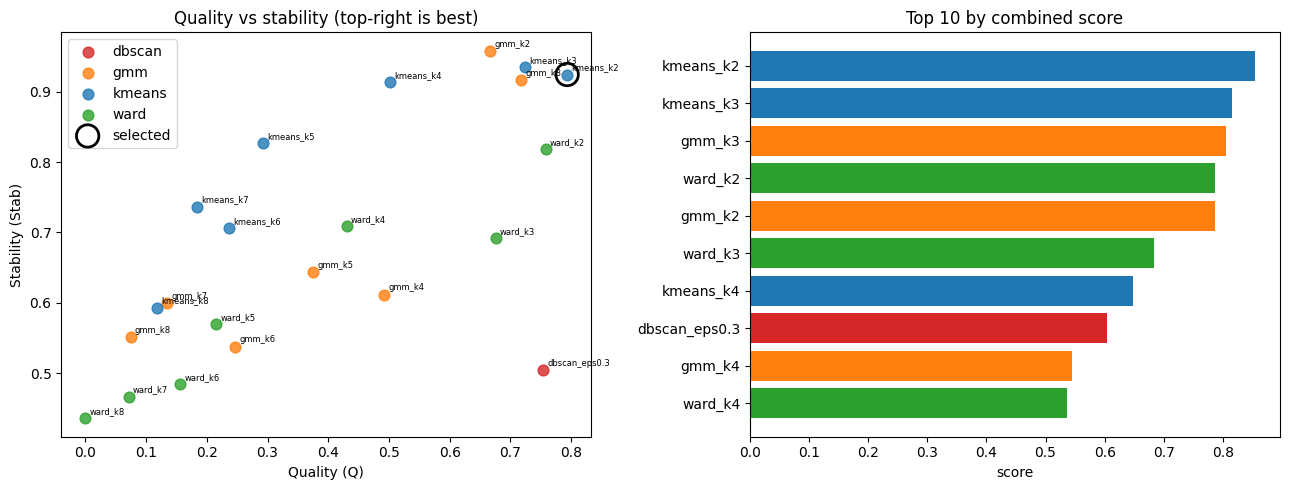

Weight sensitivity (a robust choice wins across weights):


,w_quality,best_model,score
0,0.20,gmm_k2,0.900
1,0.35,kmeans_k2,0.879
2,0.50,kmeans_k2,0.859
3,0.65,kmeans_k2,0.839
4,0.80,kmeans_k2,0.820


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
colors = {"kmeans": "tab:blue", "ward": "tab:green", "gmm": "tab:orange", "dbscan": "tab:red"}
for a, g in res.groupby("algo"):
    ax[0].scatter(g.Q, g.Stab, c=colors[a], label=a, s=60, alpha=.8)
for _, r in res.iterrows():
    ax[0].annotate(r.model, (r.Q, r.Stab), fontsize=6, xytext=(3, 3), textcoords="offset points")
c = res[res.model == CHOSEN].iloc[0]
ax[0].scatter(c.Q, c.Stab, s=260, facecolors="none", edgecolors="k", linewidths=2, label="selected")
ax[0].set_xlabel("Quality (Q)"); ax[0].set_ylabel("Stability (Stab)")
ax[0].set_title("Quality vs stability (top-right is best)"); ax[0].legend()

top = res.head(10).iloc[::-1]
ax[1].barh(top.model, top.score, color=[colors[a] for a in top.algo])
ax[1].set_title("Top 10 by combined score"); ax[1].set_xlabel("score")
plt.tight_layout(); plt.show()

# Sensitivity: weighted score w*Q + (1-w)*Stab
sens = []
for w in [0.2, 0.35, 0.5, 0.65, 0.8]:
    s = w * res.Q + (1 - w) * res.Stab
    sens.append(dict(w_quality=w, best_model=res.loc[s.idxmax(), "model"], score=round(s.max(), 3)))
print("Weight sensitivity (a robust choice wins across weights):")
display(pd.DataFrame(sens))

## 7. Per-segment stability (Jaccard)

For each segment in the chosen model, the Jaccard similarity to its best-matching cluster in each subsample is averaged. Segments below the threshold should be merged, flagged, or treated as unreliable.

In [9]:
def per_cluster_jaccard(make, ref, B=B):
    rng = np.random.default_rng(SEED)
    n = len(X)
    clusters = sorted(set(ref) - {-1})
    scores = {c: [] for c in clusters}
    for _ in range(B):
        idx = rng.choice(n, int(SUBSAMPLE_FRAC * n), replace=False)
        lab = make().fit_predict(StandardScaler().fit_transform(Xlog[idx]))
        ref_sub = ref[idx]
        for c in clusters:
            a = ref_sub == c
            best_j = 0.0
            for d in set(lab) - {-1}:
                b = lab == d
                best_j = max(best_j, (a & b).sum() / max((a | b).sum(), 1))
            scores[c].append(best_j)
    return pd.DataFrame({"segment": clusters,
                         "size": [(ref == c).sum() for c in clusters],
                         "jaccard_mean": [np.mean(scores[c]) for c in clusters],
                         "jaccard_sd": [np.std(scores[c]) for c in clusters]})

ref = ref_store[CHOSEN]
seg_stab = per_cluster_jaccard(candidates[CHOSEN], ref)
seg_stab["reliable"] = seg_stab.jaccard_mean >= JACCARD_THRESHOLD
display(seg_stab.round(3))

,segment,size,jaccard_mean,jaccard_sd,reliable
0,0,855,0.994,0.005,True
1,1,645,0.993,0.007,True


## 8. Segment profiles

,recency,frequency,monetary,size,share_%
segment,,,,,
0,146.9,3.2,83.4,855,57.0
1,10.9,16.1,646.5,645,43.0


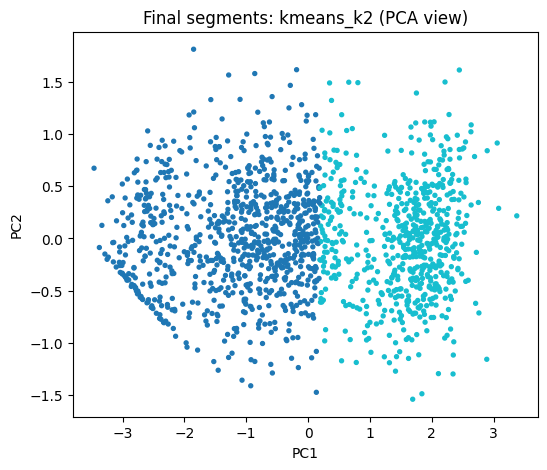

Sanity check vs known synthetic segments, ARI = 0.392


In [10]:
prof = df[FEATURES].assign(segment=ref).query("segment != -1").groupby("segment")[FEATURES].mean()
prof["size"] = pd.Series(ref).value_counts()
prof["share_%"] = (100 * prof["size"] / len(ref)).round(1)
display(prof.round(1))

Z2 = PCA(2, random_state=SEED).fit_transform(X)
plt.figure(figsize=(6, 5))
plt.scatter(Z2[:, 0], Z2[:, 1], c=ref, cmap="tab10", s=8)
plt.title(f"Final segments: {CHOSEN} (PCA view)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

if "true_segment" in df.columns:
    print("Sanity check vs known synthetic segments, ARI =",
          round(adjusted_rand_score(df.true_segment, ref), 3))

## 9. Report summary

Report for the chosen model: quality metrics, stability (mean ± SD of ARI under each perturbation), per-segment Jaccard, and the segment profiles above. Re-run this notebook on new customer data periodically to detect segment drift.

**Notes**
- Increase `B` to 100–200 for final results.
- Quality indices and stability both tend to favor small k, so keep the parsimony rule and business criteria (segment size, interpretability, actionability) in the decision.
- High stability alone is not validity; always read it together with quality and the segment profiles.